### Recovering the symbol from a travelling KdV waves

In [10]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [11]:
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV
from camera.lsmCamera import LSM
from solvers.help import *

from waves.waveGenCamera import KdVPacket

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [12]:


L   = 6
N   = 2**8
dt  = 1e-5
c1 = Camera(L,N,dt)
T = 1


amps = np.linspace(0.01,2,2)
means = np.zeros_like(amps)
ps    = L*np.ones_like(amps)

In [13]:
kdvp = KdVPacket(P_list=ps,amp_list=amps, mean_list=means, camera=c1, T= T)
H = kdvp.mainloop()

In [14]:
lsm = LSM(eta_list=H, camera=c1)
X = lsm.lsm()

In [15]:
ell, n = lsm.fit_symbol()
print(fit_table(ell,n,part='real'))


          ξ^3       ξ^2       ξ^1         ξ^0
ell -0.000006 -0.000743  0.029431 -182.264737
n    0.000040  0.044896 -0.865727  473.125017


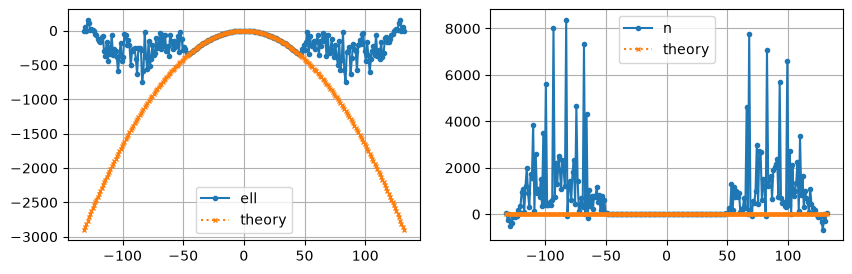

In [16]:
lsm.plot_symbol_fit(ell_t=kdVDispersion)

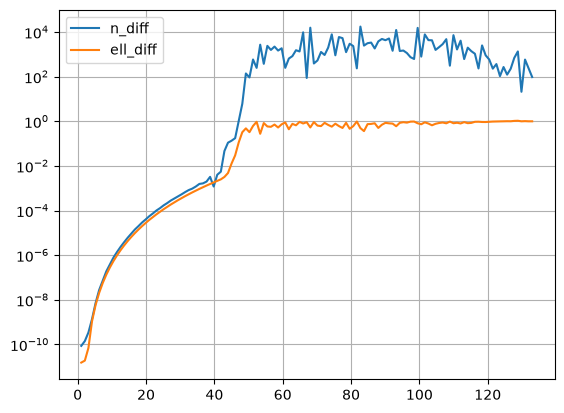

In [17]:
# We assume the symbols are symmetric
k = c1.k
order = np.argsort(k)
ko = k[order]
ko_p = ko[N//2:]

nt_pos = n_theory(ko_p)
n_pos = lsm.n[order][N//2:]

ellt_pos = kdVDispersion(ko_p)
ell_pos = lsm.ell[order][N//2:]

n_diff = np.abs((nt_pos - n_pos)/nt_pos)
ell_diff = np.abs((ellt_pos - ell_pos)/ellt_pos)


# p = 20
# plt.plot(ko_p[0:p], ell_pos[0:p])
# plt.plot(ko_p[0:p], ellt_pos[0:p])
# plt.show()


plt.semilogy(ko_p, n_diff, label = "n_diff")
plt.semilogy(ko_p, ell_diff, label = "ell_diff")
plt.legend()
plt.grid()
plt.show()

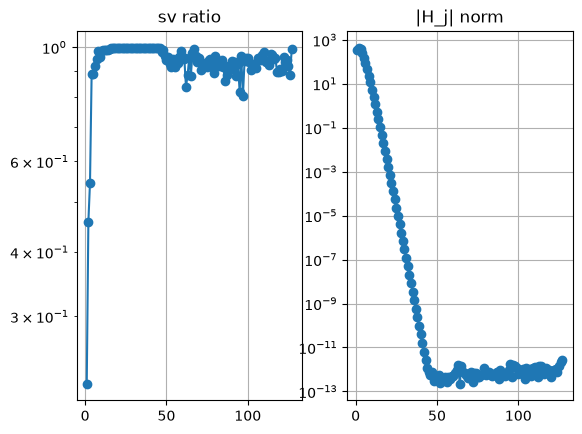

In [18]:
j = np.rint(c1.k / (2*np.pi/c1.L)).astype(int)
order = np.argsort(j)
fig, ax = plt.subplots(1, 2)
ax[0].semilogy(j[order][N//2:], lsm.sv_ratio[order][N//2:], 'o-'); ax[0].set_title("sv ratio")
ax[1].semilogy(j[order][N//2+1:], lsm.col_norm[order, 0][N//2+1:], 'o-'); ax[1].set_title("|H_j| norm")
ax[0].grid(True)
ax[1].grid(True)
plt.show()